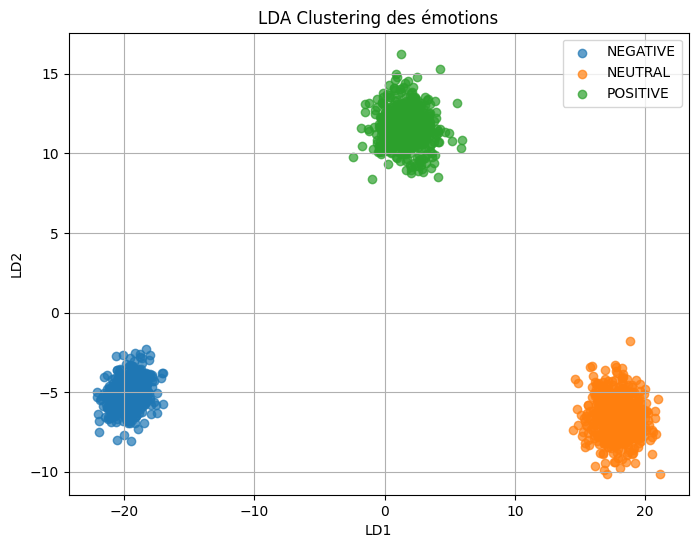

In [1]:
# Import des librairies
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA

# 1️⃣ Charger le dataset
df = pd.read_csv("/kaggle/input/vae-final-nchalla/emotions.csv")

# ⚠️ Adapte selon ton dataset :
# Supposons que la colonne "label" contient les émotions
X = df.drop("label", axis=1)   # Les features
y = df["label"]                # Les labels

# 3️⃣ Encodage des labels si ce sont des textes
le = LabelEncoder()
y_encoded = le.fit_transform(y)

# 4️⃣ Standardisation des données
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 5️⃣ Appliquer LDA (on garde 2 composantes pour visualiser)
lda = LDA(n_components=2)
X_lda = lda.fit_transform(X_scaled, y_encoded)

# 6️⃣ Création d’un DataFrame pour la visualisation
lda_df = pd.DataFrame(X_lda, columns=["LD1", "LD2"])
lda_df["label"] = y_encoded

# 7️⃣ Visualisation des clusters
plt.figure(figsize=(8, 6))
for lab in range(len(le.classes_)):
    plt.scatter(
        lda_df.loc[lda_df["label"] == lab, "LD1"],
        lda_df.loc[lda_df["label"] == lab, "LD2"],
        label=le.classes_[lab],
        alpha=0.7
    )

plt.xlabel("LD1")
plt.ylabel("LD2")
plt.title("LDA Clustering des émotions")
plt.legend()
plt.grid(True)
plt.show()


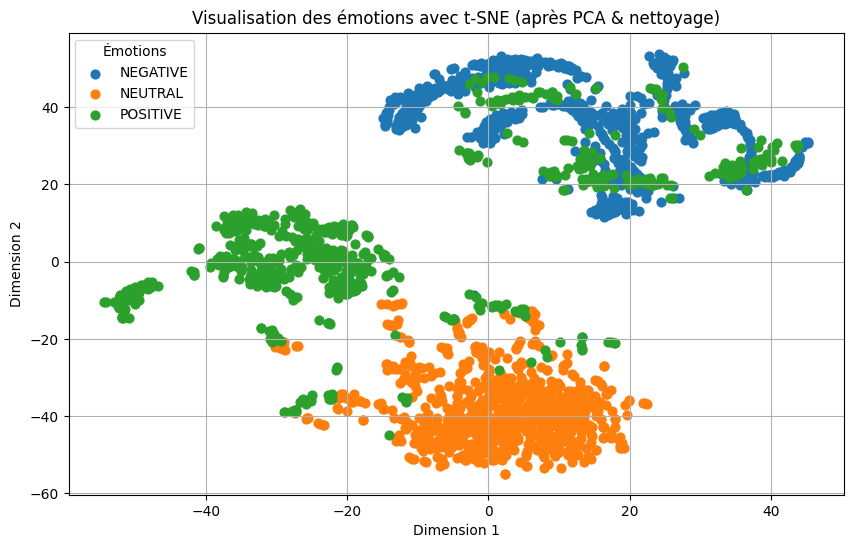

In [3]:
# 📦 Import des librairies nécessaires
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.ensemble import IsolationForest

# 1️⃣ Charger le dataset
df = pd.read_csv("/kaggle/input/vae-final-nchalla/emotions.csv")

# 2️⃣ Encoder les labels
label_col = 'label'
le = LabelEncoder()
df['label_encoded'] = le.fit_transform(df[label_col])

# 3️⃣ Séparer features et labels
X = df.drop(columns=[label_col, 'label_encoded'])
y = df['label_encoded']

# 4️⃣ Normaliser les données
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 5️⃣ Supprimer les outliers (optionnel)
iso = IsolationForest(contamination=0.02, random_state=42)
mask = iso.fit_predict(X_scaled) != -1
X_clean, y_clean = X_scaled[mask], y[mask]

# 6️⃣ Réduction préalable par PCA (stabilisation)
pca = PCA(n_components=30, random_state=42)
X_pca = pca.fit_transform(X_clean)

# 7️⃣ Appliquer t-SNE
tsne = TSNE(
    n_components=2,
    perplexity=40,
    learning_rate=300,
    n_iter=2000,
    init='pca',
    random_state=42,
    early_exaggeration=15
)
X_tsne = tsne.fit_transform(X_pca)

# 8️⃣ Visualiser les clusters
plt.figure(figsize=(10, 6))
for label in sorted(y_clean.unique()):
    subset = X_tsne[y_clean == label]
    plt.scatter(subset[:, 0], subset[:, 1], label=le.classes_[label], s=40)

plt.title("Visualisation des émotions avec t-SNE (après PCA & nettoyage)")
plt.xlabel("Dimension 1")
plt.ylabel("Dimension 2")
plt.legend(title="Émotions")
plt.grid(True)
plt.show()


Shape (features + label): (2089, 31)
Exemple de données (features + label):


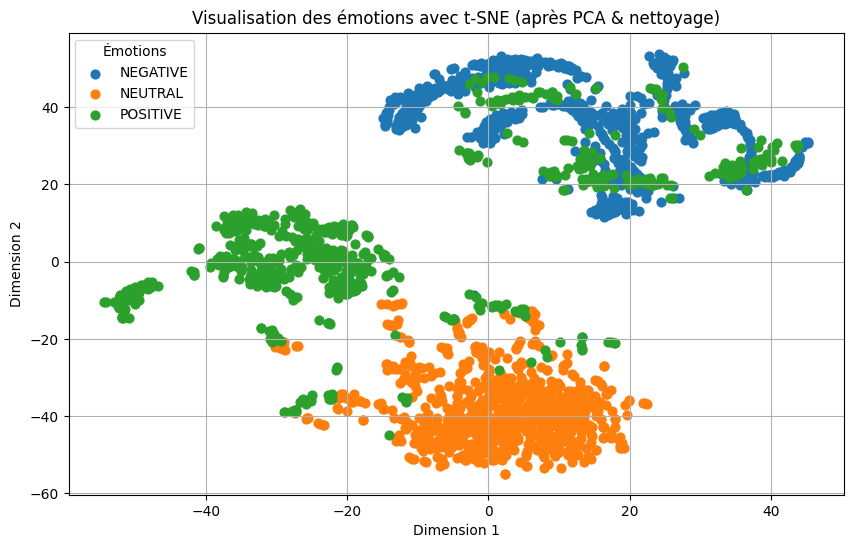

In [5]:
# 📦 Import des librairies nécessaires
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.ensemble import IsolationForest
import numpy as np

# 1️⃣ Charger le dataset
df = pd.read_csv("/kaggle/input/vae-final-nchalla/emotions.csv")

# 2️⃣ Encoder les labels
label_col = 'label'
le = LabelEncoder()
df['label_encoded'] = le.fit_transform(df[label_col])

# 3️⃣ Séparer features et labels
X = df.drop(columns=[label_col, 'label_encoded'])
y = df['label_encoded']

# 4️⃣ Normaliser les données
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 5️⃣ Supprimer les outliers (optionnel)
iso = IsolationForest(contamination=0.02, random_state=42)
mask = iso.fit_predict(X_scaled) != -1
X_clean, y_clean = X_scaled[mask], y[mask]

# 6️⃣ Réduction préalable par PCA (stabilisation)
pca = PCA(n_components=30, random_state=42)
X_pca = pca.fit_transform(X_clean)

# 🔹 Conserver les labels avec les features PCA
X_pca_with_labels = np.column_stack((X_pca, y_clean.values))  # dernière colonne = label
print("Shape (features + label):", X_pca_with_labels.shape)
print("Exemple de données (features + label):")


# 7️⃣ Appliquer t-SNE
tsne = TSNE(
    n_components=2,
    perplexity=40,
    learning_rate=300,
    n_iter=2000,
    init='pca',
    random_state=42,
    early_exaggeration=15
)
X_tsne = tsne.fit_transform(X_pca)

# 8️⃣ Visualiser les clusters
plt.figure(figsize=(10, 6))
for label in sorted(y_clean.unique()):
    subset = X_tsne[y_clean == label]
    plt.scatter(subset[:, 0], subset[:, 1], label=le.classes_[label], s=40)

plt.title("Visualisation des émotions avec t-SNE (après PCA & nettoyage)")
plt.xlabel("Dimension 1")
plt.ylabel("Dimension 2")
plt.legend(title="Émotions")
plt.grid(True)
plt.show()


Epoch [1/50] | Train Loss: 107.5120 | Test Loss: 104.3448
Epoch [2/50] | Train Loss: 90.4329 | Test Loss: 101.0292
Epoch [3/50] | Train Loss: 87.2340 | Test Loss: 97.4186
Epoch [4/50] | Train Loss: 83.9821 | Test Loss: 93.3793
Epoch [5/50] | Train Loss: 78.8111 | Test Loss: 83.8455
Epoch [6/50] | Train Loss: 70.0532 | Test Loss: 73.2785
Epoch [7/50] | Train Loss: 60.0373 | Test Loss: 63.4184
Epoch [8/50] | Train Loss: 52.5392 | Test Loss: 54.9936
Epoch [9/50] | Train Loss: 46.9493 | Test Loss: 49.4219
Epoch [10/50] | Train Loss: 43.1230 | Test Loss: 46.2154
Epoch [11/50] | Train Loss: 39.6821 | Test Loss: 42.1827
Epoch [12/50] | Train Loss: 36.3904 | Test Loss: 39.2144
Epoch [13/50] | Train Loss: 33.1781 | Test Loss: 35.6655
Epoch [14/50] | Train Loss: 30.5568 | Test Loss: 33.1682
Epoch [15/50] | Train Loss: 28.5553 | Test Loss: 30.0382
Epoch [16/50] | Train Loss: 27.6684 | Test Loss: 29.4568
Epoch [17/50] | Train Loss: 25.9709 | Test Loss: 28.5397
Epoch [18/50] | Train Loss: 25.4981 |

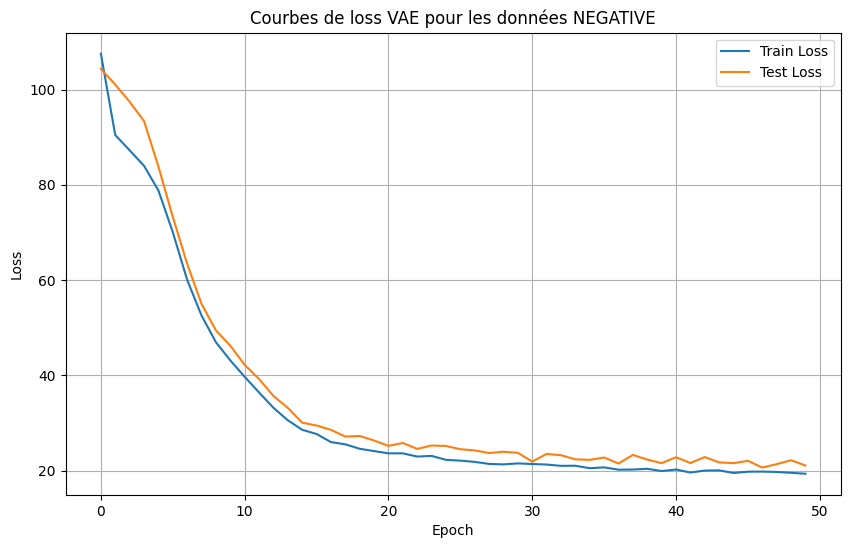

In [9]:
# 📦 Import des librairies nécessaires
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset, random_split
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# 🔹 On suppose que X_pca et y_clean sont déjà disponibles depuis ton code précédent

# 1️⃣ Filtrer uniquement les données NEGATIVE
negative_label = 0  # Ici, vérifier le code : si 'NEGATIVE' correspond à 0 dans y_clean
mask_neg = y_clean == negative_label
X_neg = X_pca[mask_neg]

# Convertir en tenseur PyTorch
X_tensor = torch.tensor(X_neg, dtype=torch.float32)

# 2️⃣ Définir le VAE
class VAE(nn.Module):
    def __init__(self, input_dim, latent_dim=10):
        super(VAE, self).__init__()
        # Encoder
        self.fc1 = nn.Linear(input_dim, 128)
        self.fc_mu = nn.Linear(128, latent_dim)
        self.fc_logvar = nn.Linear(128, latent_dim)
        # Decoder
        self.fc2 = nn.Linear(latent_dim, 128)
        self.fc3 = nn.Linear(128, input_dim)
        self.relu = nn.ReLU()
        
    def encode(self, x):
        h = self.relu(self.fc1(x))
        return self.fc_mu(h), self.fc_logvar(h)
    
    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + eps * std
    
    def decode(self, z):
        h = self.relu(self.fc2(z))
        return self.fc3(h)
    
    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        return self.decode(z), mu, logvar

# 3️⃣ Définir la loss du VAE
def vae_loss(recon_x, x, mu, logvar):
    recon_loss = nn.MSELoss()(recon_x, x)
    kl_loss = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp()) / x.size(0)
    return recon_loss + kl_loss, recon_loss.item(), kl_loss.item()

# 4️⃣ Préparer DataLoader pour train/test
dataset = TensorDataset(X_tensor)
train_size = int(0.8 * len(dataset))
test_size = len(dataset) - train_size
train_dataset, test_dataset = random_split(dataset, [train_size, test_size])

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=32)

# 5️⃣ Initialiser le modèle
input_dim = X_tensor.shape[1]
vae = VAE(input_dim=input_dim, latent_dim=10)
optimizer = optim.Adam(vae.parameters(), lr=1e-3)

# 6️⃣ Entraînement
num_epochs = 50
train_losses, test_losses = [], []

for epoch in range(num_epochs):
    vae.train()
    train_loss_epoch = 0
    for batch in train_loader:
        x_batch = batch[0]
        optimizer.zero_grad()
        recon, mu, logvar = vae(x_batch)
        loss, _, _ = vae_loss(recon, x_batch, mu, logvar)
        loss.backward()
        optimizer.step()
        train_loss_epoch += loss.item()
    train_losses.append(train_loss_epoch / len(train_loader))
    
    # Validation/test
    vae.eval()
    test_loss_epoch = 0
    with torch.no_grad():
        for batch in test_loader:
            x_batch = batch[0]
            recon, mu, logvar = vae(x_batch)
            loss, _, _ = vae_loss(recon, x_batch, mu, logvar)
            test_loss_epoch += loss.item()
    test_losses.append(test_loss_epoch / len(test_loader))
    
    print(f"Epoch [{epoch+1}/{num_epochs}] | Train Loss: {train_losses[-1]:.4f} | Test Loss: {test_losses[-1]:.4f}")

# 7️⃣ Plot des courbes de loss
plt.figure(figsize=(10,6))
plt.plot(train_losses, label='Train Loss')
plt.plot(test_losses, label='Test Loss')
plt.title("Courbes de loss VAE pour les données NEGATIVE")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()


Epoch [1/50] | Train Loss: 61.0665 | Test Loss: 41.1899
Epoch [2/50] | Train Loss: 45.4454 | Test Loss: 40.7490
Epoch [3/50] | Train Loss: 43.5729 | Test Loss: 38.8974
Epoch [4/50] | Train Loss: 43.3917 | Test Loss: 37.8115
Epoch [5/50] | Train Loss: 43.2918 | Test Loss: 37.2268
Epoch [6/50] | Train Loss: 41.8956 | Test Loss: 36.4193
Epoch [7/50] | Train Loss: 41.1344 | Test Loss: 35.5733
Epoch [8/50] | Train Loss: 39.8029 | Test Loss: 34.3828
Epoch [9/50] | Train Loss: 39.0781 | Test Loss: 33.1797
Epoch [10/50] | Train Loss: 38.4489 | Test Loss: 30.9820
Epoch [11/50] | Train Loss: 36.6751 | Test Loss: 29.7152
Epoch [12/50] | Train Loss: 34.1900 | Test Loss: 28.9015
Epoch [13/50] | Train Loss: 32.9218 | Test Loss: 27.6027
Epoch [14/50] | Train Loss: 31.8529 | Test Loss: 26.7373
Epoch [15/50] | Train Loss: 31.0457 | Test Loss: 24.7286
Epoch [16/50] | Train Loss: 30.5034 | Test Loss: 24.6815
Epoch [17/50] | Train Loss: 29.6248 | Test Loss: 24.1216
Epoch [18/50] | Train Loss: 29.5485 | Te

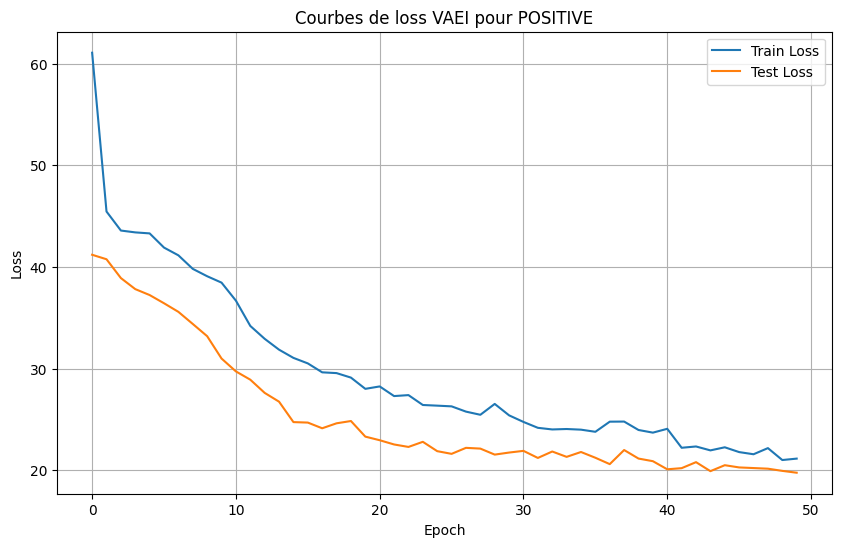

In [15]:
# 🔹 Filtrer uniquement les données POSITIVE
positive_label = 2  # Vérifier le code : adapter selon y_clean si 'POSITIVE' = 2
mask_pos = y_clean == positive_label
X_pos = X_pca[mask_pos]

# Convertir en tenseur PyTorch
X_tensor = torch.tensor(X_pos, dtype=torch.float32)

# Définir le VAE
class VAEI(nn.Module):
    def __init__(self, input_dim, latent_dim=10):
        super(VAEI, self).__init__()
        self.fc1 = nn.Linear(input_dim, 128)
        self.fc_mu = nn.Linear(128, latent_dim)
        self.fc_logvar = nn.Linear(128, latent_dim)
        self.fc2 = nn.Linear(latent_dim, 128)
        self.fc3 = nn.Linear(128, input_dim)
        self.relu = nn.ReLU()
        
    def encode(self, x):
        h = self.relu(self.fc1(x))
        return self.fc_mu(h), self.fc_logvar(h)
    
    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + eps * std
    
    def decode(self, z):
        h = self.relu(self.fc2(z))
        return self.fc3(h)
    
    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        return self.decode(z), mu, logvar

# Loss
def vaei_loss(recon_x, x, mu, logvar):
    recon_loss = nn.MSELoss()(recon_x, x)
    kl_loss = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp()) / x.size(0)
    return recon_loss + kl_loss, recon_loss.item(), kl_loss.item()

# DataLoader
dataset = torch.utils.data.TensorDataset(X_tensor)
train_size = int(0.8 * len(dataset))
test_size = len(dataset) - train_size
train_dataset, test_dataset = torch.utils.data.random_split(dataset, [train_size, test_size])
train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=32, shuffle=True)
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=32)

# Modèle
input_dim = X_tensor.shape[1]
vaei = VAEI(input_dim=input_dim, latent_dim=10)
optimizer = torch.optim.Adam(vaei.parameters(), lr=1e-3)

# Entraînement
num_epochs = 50
train_losses, test_losses = [], []

for epoch in range(num_epochs):
    vaei.train()
    train_loss_epoch = 0
    for batch in train_loader:
        x_batch = batch[0]
        optimizer.zero_grad()
        recon, mu, logvar = vaei(x_batch)
        loss, _, _ = vaei_loss(recon, x_batch, mu, logvar)
        loss.backward()
        optimizer.step()
        train_loss_epoch += loss.item()
    train_losses.append(train_loss_epoch / len(train_loader))
    
    vaei.eval()
    test_loss_epoch = 0
    with torch.no_grad():
        for batch in test_loader:
            x_batch = batch[0]
            recon, mu, logvar = vaei(x_batch)
            loss, _, _ = vaei_loss(recon, x_batch, mu, logvar)
            test_loss_epoch += loss.item()
    test_losses.append(test_loss_epoch / len(test_loader))
    
    print(f"Epoch [{epoch+1}/{num_epochs}] | Train Loss: {train_losses[-1]:.4f} | Test Loss: {test_losses[-1]:.4f}")

# Plot
plt.figure(figsize=(10,6))
plt.plot(train_losses, label='Train Loss')
plt.plot(test_losses, label='Test Loss')
plt.title("Courbes de loss VAEI pour POSITIVE")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()


Epoch [1/50] | Train Loss: 18.5820 | Test Loss: 18.0146
Epoch [2/50] | Train Loss: 16.1578 | Test Loss: 16.4021
Epoch [3/50] | Train Loss: 14.7322 | Test Loss: 15.1569
Epoch [4/50] | Train Loss: 13.4209 | Test Loss: 13.7209
Epoch [5/50] | Train Loss: 12.1237 | Test Loss: 12.4466
Epoch [6/50] | Train Loss: 10.5930 | Test Loss: 10.8730
Epoch [7/50] | Train Loss: 9.0014 | Test Loss: 9.0245
Epoch [8/50] | Train Loss: 7.5712 | Test Loss: 8.1698
Epoch [9/50] | Train Loss: 6.6841 | Test Loss: 7.2877
Epoch [10/50] | Train Loss: 6.1716 | Test Loss: 7.0608
Epoch [11/50] | Train Loss: 5.9892 | Test Loss: 6.8612
Epoch [12/50] | Train Loss: 5.7933 | Test Loss: 6.8430
Epoch [13/50] | Train Loss: 5.5074 | Test Loss: 6.7148
Epoch [14/50] | Train Loss: 5.5079 | Test Loss: 6.4816
Epoch [15/50] | Train Loss: 5.2677 | Test Loss: 6.0024
Epoch [16/50] | Train Loss: 5.0805 | Test Loss: 6.2642
Epoch [17/50] | Train Loss: 4.9767 | Test Loss: 5.8665
Epoch [18/50] | Train Loss: 4.7532 | Test Loss: 5.7228
Epoch [

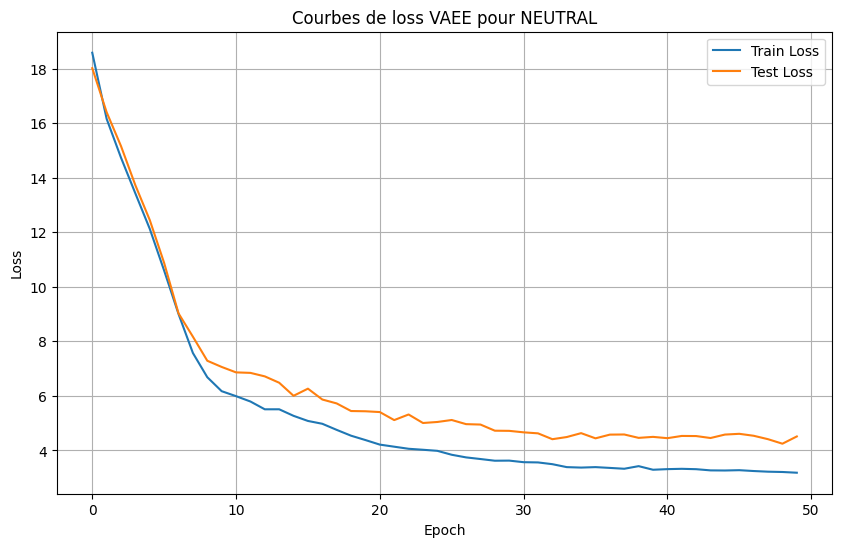

In [12]:
# 🔹 Filtrer uniquement les données NEUTRAL
neutral_label = 1  # Vérifier le code : adapter selon y_clean si 'NEUTRAL' = 1
mask_neu = y_clean == neutral_label
X_neu = X_pca[mask_neu]

# Convertir en tenseur PyTorch
X_tensor = torch.tensor(X_neu, dtype=torch.float32)

# Définir le VAE (même architecture)
class VAEE(nn.Module):
    def __init__(self, input_dim, latent_dim=10):
        super(VAEE, self).__init__()
        self.fc1 = nn.Linear(input_dim, 128)
        self.fc_mu = nn.Linear(128, latent_dim)
        self.fc_logvar = nn.Linear(128, latent_dim)
        self.fc2 = nn.Linear(latent_dim, 128)
        self.fc3 = nn.Linear(128, input_dim)
        self.relu = nn.ReLU()
        
    def encode(self, x):
        h = self.relu(self.fc1(x))
        return self.fc_mu(h), self.fc_logvar(h)
    
    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + eps * std
    
    def decode(self, z):
        h = self.relu(self.fc2(z))
        return self.fc3(h)
    
    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        return self.decode(z), mu, logvar

# Loss
def vaee_loss(recon_x, x, mu, logvar):
    recon_loss = nn.MSELoss()(recon_x, x)
    kl_loss = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp()) / x.size(0)
    return recon_loss + kl_loss, recon_loss.item(), kl_loss.item()

# DataLoader
dataset = torch.utils.data.TensorDataset(X_tensor)
train_size = int(0.8 * len(dataset))
test_size = len(dataset) - train_size
train_dataset, test_dataset = torch.utils.data.random_split(dataset, [train_size, test_size])
train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=32, shuffle=True)
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=32)

# Modèle
input_dim = X_tensor.shape[1]
vaee = VAEE(input_dim=input_dim, latent_dim=10)
optimizer = torch.optim.Adam(vaee.parameters(), lr=1e-3)

# Entraînement
num_epochs = 50
train_losses, test_losses = [], []

for epoch in range(num_epochs):
    vaee.train()
    train_loss_epoch = 0
    for batch in train_loader:
        x_batch = batch[0]
        optimizer.zero_grad()
        recon, mu, logvar = vaee(x_batch)
        loss, _, _ = vaee_loss(recon, x_batch, mu, logvar)
        loss.backward()
        optimizer.step()
        train_loss_epoch += loss.item()
    train_losses.append(train_loss_epoch / len(train_loader))
    
    vaee.eval()
    test_loss_epoch = 0
    with torch.no_grad():
        for batch in test_loader:
            x_batch = batch[0]
            recon, mu, logvar = vaee(x_batch)
            loss, _, _ = vaee_loss(recon, x_batch, mu, logvar)
            test_loss_epoch += loss.item()
    test_losses.append(test_loss_epoch / len(test_loader))
    
    print(f"Epoch [{epoch+1}/{num_epochs}] | Train Loss: {train_losses[-1]:.4f} | Test Loss: {test_losses[-1]:.4f}")

# Plot
plt.figure(figsize=(10,6))
plt.plot(train_losses, label='Train Loss')
plt.plot(test_losses, label='Test Loss')
plt.title("Courbes de loss VAEE pour NEUTRAL")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()


In [19]:
# 📦 Import des librairies nécessaires
import torch
import torch.nn as nn
import pandas as pd

# 🔹 Supposons que ton VAE a déjà été défini et entraîné
# et que `input_dim` et `vae` existent

# ------------------------------
# 1️⃣ Générer 400 nouvelles données
# ------------------------------
vae.eval()  # Mode évaluation
num_samples = 400
latent_dim = 10  # Doit correspondre à celui utilisé lors de l'entraînement

# Échantillonnage aléatoire dans l'espace latent
z = torch.randn(num_samples, latent_dim)
with torch.no_grad():
    generated_data = vae.decode(z)

# Convertir en numpy
generated_data_np = generated_data.numpy()

# ------------------------------
# 2️⃣ Créer un DataFrame avec les colonnes features
# ------------------------------
df_generated_neg = pd.DataFrame(
    generated_data_np, 
    columns=[f'feature_{i}' for i in range(generated_data_np.shape[1])]
)

# ------------------------------
# 3️⃣ Ajouter le label 'NEGATIVE'
# ------------------------------
df_generated_neg['label'] = 'NEGATIVE'  # ou 0 si tu préfères format numérique

# ------------------------------
# 4️⃣ Aperçu
# ------------------------------
print(f"Shape: {df_generated_neg.shape}")


Shape: (400, 31)


In [18]:
# 📦 Import des librairies nécessaires
import torch
import torch.nn as nn
import pandas as pd

# 🔹 Supposons que ton VAEI a déjà été défini et entraîné
# et que `input_dim` et `vaei` existent

# ------------------------------
# 1️⃣ Générer 400 nouvelles données POSITIVE
# ------------------------------
vaei.eval()  # Mode évaluation
num_samples = 400
latent_dim = 10  # Doit correspondre à celui utilisé lors de l'entraînement

# Échantillonnage aléatoire dans l'espace latent
z = torch.randn(num_samples, latent_dim)
with torch.no_grad():
    generated_data = vaei.decode(z)

# Convertir en numpy
generated_data_np = generated_data.numpy()

# ------------------------------
# 2️⃣ Créer un DataFrame avec les colonnes features
# ------------------------------
df_generated_pos = pd.DataFrame(
    generated_data_np,
    columns=[f'feature_{i}' for i in range(generated_data_np.shape[1])]
)

# ------------------------------
# 3️⃣ Ajouter le label 'POSITIVE'
# ------------------------------
df_generated_pos['label'] = 'POSITIVE'  # ou 2 si tu veux garder le format numérique

# ------------------------------
# 4️⃣ Aperçu

print(f"Shape: {df_generated_pos.shape}")


Shape: (400, 31)


In [21]:
# 📦 Import des librairies nécessaires
import torch
import torch.nn as nn
import pandas as pd

# 🔹 Supposons que ton VAEE a déjà été défini et entraîné
# et que `input_dim` et `vaee` existent

# ------------------------------
# 1️⃣ Générer 400 nouvelles données NEUTRAL
# ------------------------------
vaee.eval()  # Mode évaluation
num_samples = 400
latent_dim = 10  # Doit correspondre à celui utilisé lors de l'entraînement

# Échantillonnage aléatoire dans l'espace latent
z = torch.randn(num_samples, latent_dim)
with torch.no_grad():
    generated_data = vaee.decode(z)

# Convertir en numpy
generated_data_np = generated_data.numpy()

# ------------------------------
# 2️⃣ Créer un DataFrame avec les colonnes features
# ------------------------------
df_generated_neu = pd.DataFrame(
    generated_data_np,
    columns=[f'feature_{i}' for i in range(generated_data_np.shape[1])]
)

# ------------------------------
# 3️⃣ Ajouter le label 'NEUTRAL'
# ------------------------------
df_generated_neu['label'] = 'NEUTRAL'  # ou 1 si tu veux garder le format numérique

# ------------------------------
# 4️⃣ Aperçu
# -----------------------------
print(f"Shape: {df_generated_neu.shape}")


Shape: (400, 31)


In [22]:
# 📦 Importer pandas si ce n'est pas déjà fait
import pandas as pd

# 🔹 Concaténer toutes les données générées
new_data_generated = pd.concat(
    [df_generated_neg, df_generated_pos, df_generated_neu],
    ignore_index=True
)

# 🔹 Aperçu du nouveau DataFrame

print(f"Shape: {new_data_generated.shape}")
print(new_data_generated['label'].value_counts())  # Vérifier les labels


Shape: (1200, 31)
label
NEGATIVE    400
POSITIVE    400
NEUTRAL     400
Name: count, dtype: int64


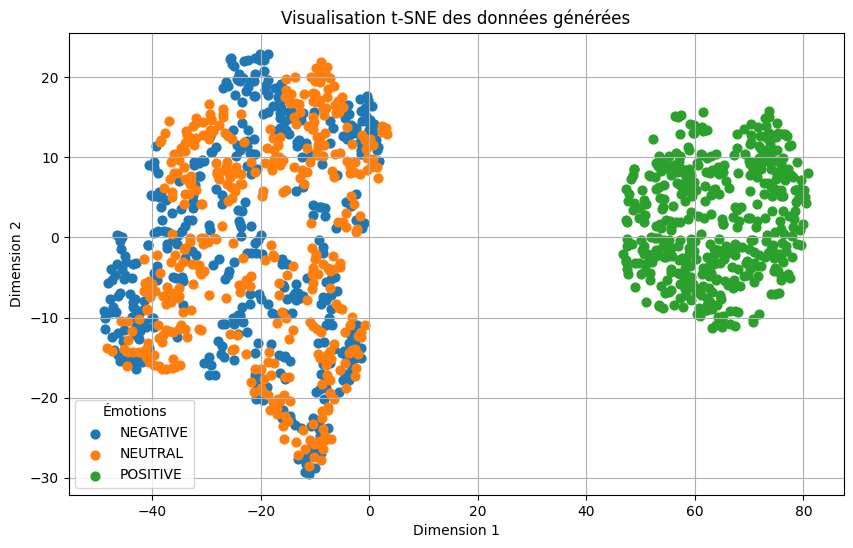

In [24]:
# 📦 Import des librairies nécessaires
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE

# ------------------------------
# 1️⃣ Préparer les données
# ------------------------------
X_generated = new_data_generated.drop('label', axis=1).values  # Features
y_generated = new_data_generated['label'].values               # Labels

# ------------------------------
# 2️⃣ Appliquer t-SNE
# ------------------------------
tsneee = TSNE(
    n_components=2,
    perplexity=40,
    learning_rate=300,
    n_iter=2000,
    init='pca',
    random_state=42,
    early_exaggeration=15
)
X_tsne = tsneee.fit_transform(X_generated)

# ------------------------------
# 3️⃣ Visualiser les clusters
# ------------------------------
plt.figure(figsize=(10, 6))
labels_unique = sorted(list(set(y_generated)))

for label in labels_unique:
    subset = X_tsne[y_generated == label]
    plt.scatter(subset[:, 0], subset[:, 1], label=label, s=40)

plt.title("Visualisation t-SNE des données générées")
plt.xlabel("Dimension 1")
plt.ylabel("Dimension 2")
plt.legend(title="Émotions")
plt.grid(True)
plt.show()


In [25]:
import pandas as pd
import numpy as np

# ------------------------------
# 1️⃣ Convertir X_pca_with_labels en DataFrame
# ------------------------------
n_features = X_pca_with_labels.shape[1] - 1  # dernière colonne = label
df_real_pca = pd.DataFrame(
    X_pca_with_labels[:, :n_features],
    columns=[f'feature_{i}' for i in range(n_features)]
)
df_real_pca['label'] = X_pca_with_labels[:, -1]  # ajouter la colonne label

# Si tu veux, transformer les labels numériques en noms (facultatif)
label_mapping = dict(zip(range(len(le.classes_)), le.classes_))
df_real_pca['label'] = df_real_pca['label'].map(label_mapping)

# ------------------------------
# 2️⃣ Vérifier new_data_generated
# ------------------------------
# Il doit déjà contenir les colonnes 'feature_0', ..., 'feature_n' + 'label'

# ------------------------------
# 3️⃣ Ajuster les noms des colonnes si nécessaire
# ------------------------------
# Pour s'assurer que les colonnes correspondent aux features PCA
# On renomme si nombre de colonnes différent
if df_real_pca.shape[1] != new_data_generated.shape[1]:
    new_data_generated = new_data_generated.rename(
        columns={col: f'feature_{i}' for i, col in enumerate(new_data_generated.columns[:-1])}
    )

# ------------------------------
# 4️⃣ Combiner les DataFrames
# ------------------------------
combined_df = pd.concat([df_real_pca, new_data_generated], ignore_index=True)

# ------------------------------
# 5️⃣ Aperçu
# ------------------------------
print(combined_df.head())
print(f"Shape combined: {combined_df.shape}")
print(combined_df['label'].value_counts())


   feature_0  feature_1  feature_2  feature_3  feature_4  feature_5  \
0  38.554294  23.317277 -20.697214   0.355129  -1.908385   1.332032   
1 -20.251669  -2.229397  -0.694271  -3.166467  -3.273202  -1.152611   
2  37.494892 -14.527465   7.203619 -14.699690   6.785880   7.235308   
3   3.588593 -21.051864  25.068164  -0.131422  -1.914885   2.420071   
4 -23.435529  -2.445589  -0.026274 -12.315425   4.872991   6.869900   

   feature_6  feature_7  feature_8  feature_9  ...  feature_21  feature_22  \
0   0.463412   1.198755  -0.980067   0.379163  ...   -0.054097    0.410740   
1  -0.741940  -1.902007   2.982982  -0.281540  ...    0.788540   -0.264372   
2 -19.643193  -2.037873   1.555122   7.239474  ...    7.018162   -1.409330   
3   0.279087  -1.929000  -3.094361   5.806470  ...   -1.753669    0.983988   
4  -7.089274  -2.100758  -1.974620   6.387501  ...    5.687261   -4.450016   

   feature_23  feature_24  feature_25  feature_26  feature_27  feature_28  \
0    0.945489    2.339542  

claasifcation

In [27]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

# 1️⃣ Séparer features et labels
X = combined_df.drop('label', axis=1).values
y = combined_df['label'].values

# 2️⃣ Split train/test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 3️⃣ Entraîner Random Forest
rf_model = RandomForestClassifier(n_estimators=200, random_state=42)
rf_model.fit(X_train, y_train)

# 4️⃣ Accuracy sur train
y_train_pred = rf_model.predict(X_train)
train_accuracy = accuracy_score(y_train, y_train_pred)

# 5️⃣ Accuracy sur test
y_test_pred = rf_model.predict(X_test)
test_accuracy = accuracy_score(y_test, y_test_pred)

print(f"✅ Train Accuracy: {train_accuracy:.4f}")
print(f"✅ Test Accuracy: {test_accuracy:.4f}")


✅ Train Accuracy: 1.0000
✅ Test Accuracy: 0.9438


In [29]:
import xgboost as xgb
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score

# ------------------------------
# 1️⃣ Séparer features et labels
# ------------------------------
X = combined_df.drop('label', axis=1).values
y_labels = combined_df['label'].values

# ------------------------------
# 2️⃣ Encoder les labels en entiers
# ------------------------------
le_xgb = LabelEncoder()
y = le_xgb.fit_transform(y_labels)  # 'NEGATIVE' -> 0, 'NEUTRAL' -> 1, 'POSITIVE' -> 2

# ------------------------------
# 3️⃣ Split train/test
# ------------------------------
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# ------------------------------
# 4️⃣ Initialiser et entraîner XGBoost
# ------------------------------
xgb_model = xgb.XGBClassifier(
    n_estimators=200,
    max_depth=6,
    learning_rate=0.1,
    use_label_encoder=False,
    eval_metric='mlogloss',
    random_state=42
)
xgb_model.fit(X_train, y_train)

# ------------------------------
# 5️⃣ Accuracy sur train
# ------------------------------
y_train_pred = xgb_model.predict(X_train)
train_accuracy = accuracy_score(y_train, y_train_pred)

# ------------------------------
# 6️⃣ Accuracy sur test
# ------------------------------
y_test_pred = xgb_model.predict(X_test)
test_accuracy = accuracy_score(y_test, y_test_pred)

print(f"✅ Train Accuracy: {train_accuracy:.4f}")
print(f"✅ Test Accuracy: {test_accuracy:.4f}")


✅ Train Accuracy: 1.0000
✅ Test Accuracy: 0.9696


Epoch 1/50 | Train Loss: 0.5388, Train Acc: 0.7780 | Test Loss: 0.4136, Test Acc: 0.8313
Epoch 2/50 | Train Loss: 0.3818, Train Acc: 0.8377 | Test Loss: 0.3526, Test Acc: 0.8480
Epoch 3/50 | Train Loss: 0.3343, Train Acc: 0.8499 | Test Loss: 0.3483, Test Acc: 0.8374
Epoch 4/50 | Train Loss: 0.3077, Train Acc: 0.8559 | Test Loss: 0.2899, Test Acc: 0.8556
Epoch 5/50 | Train Loss: 0.2629, Train Acc: 0.8738 | Test Loss: 0.2760, Test Acc: 0.8860
Epoch 6/50 | Train Loss: 0.2274, Train Acc: 0.8951 | Test Loss: 0.2617, Test Acc: 0.8723
Epoch 7/50 | Train Loss: 0.2135, Train Acc: 0.8970 | Test Loss: 0.2286, Test Acc: 0.9058
Epoch 8/50 | Train Loss: 0.1836, Train Acc: 0.9156 | Test Loss: 0.2055, Test Acc: 0.9149
Epoch 9/50 | Train Loss: 0.1648, Train Acc: 0.9274 | Test Loss: 0.2117, Test Acc: 0.8921
Epoch 10/50 | Train Loss: 0.1468, Train Acc: 0.9399 | Test Loss: 0.1835, Test Acc: 0.9027
Epoch 11/50 | Train Loss: 0.1375, Train Acc: 0.9430 | Test Loss: 0.2202, Test Acc: 0.8815
Epoch 12/50 | Train

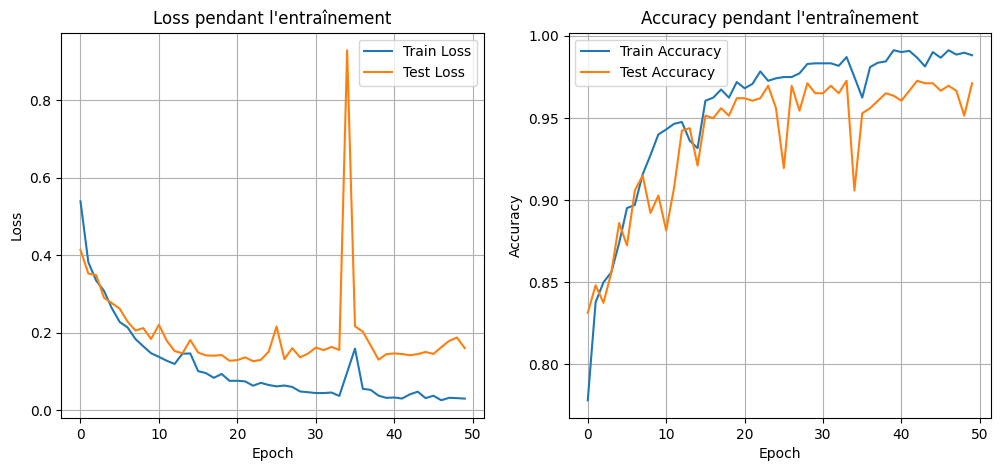

In [30]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset, random_split
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder
import numpy as np

# ------------------------------
# 1️⃣ Préparer les données
# ------------------------------
X = combined_df.drop('label', axis=1).values.astype(np.float32)
y_labels = combined_df['label'].values

# Encoder les labels en entiers
le_nn = LabelEncoder()
y = le_nn.fit_transform(y_labels)
y = torch.tensor(y, dtype=torch.long)  # nécessaire pour CrossEntropyLoss

X = torch.tensor(X, dtype=torch.float32)

# Créer dataset PyTorch
dataset = TensorDataset(X, y)

# Split train/test
train_size = int(0.8 * len(dataset))
test_size = len(dataset) - train_size
train_dataset, test_dataset = random_split(dataset, [train_size, test_size])

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

# ------------------------------
# 2️⃣ Définir le modèle
# ------------------------------
class SimpleNN(nn.Module):
    def __init__(self, input_dim, hidden_dim=128, output_dim=3):
        super(SimpleNN, self).__init__()
        self.fc1 = nn.Linear(input_dim, hidden_dim)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(hidden_dim, hidden_dim)
        self.fc3 = nn.Linear(hidden_dim, output_dim)
    
    def forward(self, x):
        x = self.relu(self.fc1(x))
        x = self.relu(self.fc2(x))
        x = self.fc3(x)
        return x

input_dim = X.shape[1]
model = SimpleNN(input_dim=input_dim)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=1e-3)

# ------------------------------
# 3️⃣ Entraînement
# ------------------------------
num_epochs = 50
train_losses, test_losses = [], []
train_accs, test_accs = [], []

for epoch in range(num_epochs):
    # Train
    model.train()
    running_loss = 0
    correct, total = 0, 0
    for xb, yb in train_loader:
        optimizer.zero_grad()
        outputs = model(xb)
        loss = criterion(outputs, yb)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * xb.size(0)
        
        # Accuracy
        _, predicted = torch.max(outputs, 1)
        correct += (predicted == yb).sum().item()
        total += yb.size(0)
    
    train_losses.append(running_loss / total)
    train_accs.append(correct / total)
    
    # Test
    model.eval()
    running_loss = 0
    correct, total = 0, 0
    with torch.no_grad():
        for xb, yb in test_loader:
            outputs = model(xb)
            loss = criterion(outputs, yb)
            running_loss += loss.item() * xb.size(0)
            _, predicted = torch.max(outputs, 1)
            correct += (predicted == yb).sum().item()
            total += yb.size(0)
    
    test_losses.append(running_loss / total)
    test_accs.append(correct / total)
    
    print(f"Epoch {epoch+1}/{num_epochs} | Train Loss: {train_losses[-1]:.4f}, Train Acc: {train_accs[-1]:.4f} | Test Loss: {test_losses[-1]:.4f}, Test Acc: {test_accs[-1]:.4f}")

# ------------------------------
# 4️⃣ Plot Loss et Accuracy
# ------------------------------
plt.figure(figsize=(12,5))

# Loss
plt.subplot(1,2,1)
plt.plot(train_losses, label='Train Loss')
plt.plot(test_losses, label='Test Loss')
plt.title("Loss pendant l'entraînement")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

# Accuracy
plt.subplot(1,2,2)
plt.plot(train_accs, label='Train Accuracy')
plt.plot(test_accs, label='Test Accuracy')
plt.title("Accuracy pendant l'entraînement")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.show()


Epoch 1/50 | Train Loss: 0.6699, Train Acc: 0.7267 | Test Loss: 0.3783, Test Acc: 0.8511
Epoch 2/50 | Train Loss: 0.4823, Train Acc: 0.7940 | Test Loss: 0.3781, Test Acc: 0.8511
Epoch 3/50 | Train Loss: 0.4229, Train Acc: 0.8168 | Test Loss: 0.3545, Test Acc: 0.8663
Epoch 4/50 | Train Loss: 0.3984, Train Acc: 0.8187 | Test Loss: 0.3535, Test Acc: 0.8571
Epoch 5/50 | Train Loss: 0.3903, Train Acc: 0.8290 | Test Loss: 0.3543, Test Acc: 0.8602
Epoch 6/50 | Train Loss: 0.3641, Train Acc: 0.8350 | Test Loss: 0.3497, Test Acc: 0.8739
Epoch 7/50 | Train Loss: 0.3582, Train Acc: 0.8347 | Test Loss: 0.3167, Test Acc: 0.8754
Epoch 8/50 | Train Loss: 0.3250, Train Acc: 0.8483 | Test Loss: 0.3165, Test Acc: 0.8784
Epoch 9/50 | Train Loss: 0.3099, Train Acc: 0.8442 | Test Loss: 0.3033, Test Acc: 0.8754
Epoch 10/50 | Train Loss: 0.2855, Train Acc: 0.8582 | Test Loss: 0.3134, Test Acc: 0.8891
Epoch 11/50 | Train Loss: 0.2847, Train Acc: 0.8537 | Test Loss: 0.3167, Test Acc: 0.8495
Epoch 12/50 | Train

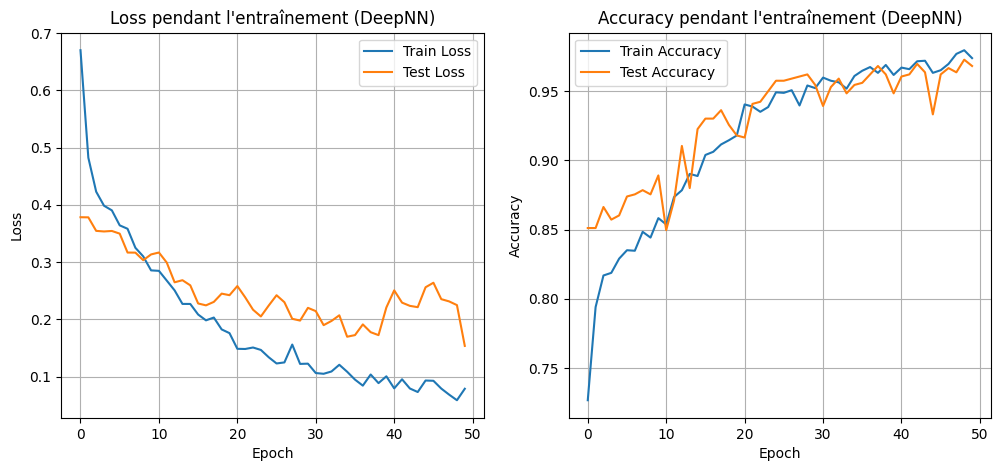

In [31]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset, random_split
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder
import numpy as np

# ------------------------------
# Préparer les données
# ------------------------------
X = combined_df.drop('label', axis=1).values.astype(np.float32)
y_labels = combined_df['label'].values

le_nn = LabelEncoder()
y = le_nn.fit_transform(y_labels)
y = torch.tensor(y, dtype=torch.long)
X = torch.tensor(X, dtype=torch.float32)

dataset = TensorDataset(X, y)
train_size = int(0.8 * len(dataset))
test_size = len(dataset) - train_size
train_dataset, test_dataset = random_split(dataset, [train_size, test_size])

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

# ------------------------------
# Définir un autre modèle (plus profond + Dropout)
# ------------------------------
class DeepNN(nn.Module):
    def __init__(self, input_dim, hidden_dims=[256, 128, 64], output_dim=3, dropout=0.3):
        super(DeepNN, self).__init__()
        layers = []
        prev_dim = input_dim
        for h_dim in hidden_dims:
            layers.append(nn.Linear(prev_dim, h_dim))
            layers.append(nn.ReLU())
            layers.append(nn.Dropout(dropout))
            prev_dim = h_dim
        layers.append(nn.Linear(prev_dim, output_dim))
        self.network = nn.Sequential(*layers)
    
    def forward(self, x):
        return self.network(x)

input_dim = X.shape[1]
model = DeepNN(input_dim=input_dim)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=1e-3)

# ------------------------------
# Entraînement
# ------------------------------
num_epochs = 50
train_losses, test_losses = [], []
train_accs, test_accs = [], []

for epoch in range(num_epochs):
    # Train
    model.train()
    running_loss = 0
    correct, total = 0, 0
    for xb, yb in train_loader:
        optimizer.zero_grad()
        outputs = model(xb)
        loss = criterion(outputs, yb)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * xb.size(0)
        _, predicted = torch.max(outputs, 1)
        correct += (predicted == yb).sum().item()
        total += yb.size(0)
    train_losses.append(running_loss / total)
    train_accs.append(correct / total)
    
    # Test
    model.eval()
    running_loss = 0
    correct, total = 0, 0
    with torch.no_grad():
        for xb, yb in test_loader:
            outputs = model(xb)
            loss = criterion(outputs, yb)
            running_loss += loss.item() * xb.size(0)
            _, predicted = torch.max(outputs, 1)
            correct += (predicted == yb).sum().item()
            total += yb.size(0)
    test_losses.append(running_loss / total)
    test_accs.append(correct / total)
    
    print(f"Epoch {epoch+1}/{num_epochs} | Train Loss: {train_losses[-1]:.4f}, Train Acc: {train_accs[-1]:.4f} | Test Loss: {test_losses[-1]:.4f}, Test Acc: {test_accs[-1]:.4f}")

# ------------------------------
# Plot Loss et Accuracy
# ------------------------------
plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.plot(train_losses, label='Train Loss')
plt.plot(test_losses, label='Test Loss')
plt.title("Loss pendant l'entraînement (DeepNN)")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.subplot(1,2,2)
plt.plot(train_accs, label='Train Accuracy')
plt.plot(test_accs, label='Test Accuracy')
plt.title("Accuracy pendant l'entraînement (DeepNN)")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.show()


/// parte gan 